# Final results

### Final results and statistics of all runs

Author: Mathias Husted

In [33]:
import pandas as pd
import sys
sys.path.append("../shared")
from scoring import wilson_score_interval
from llm_run_loader import load_run
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

BENCHMARK_PATH = "../../data/dataset/benchmark.csv"
FINAL_PATH = f"../../results/final"
RUNS_PATH = f"../../results/llm"

benchmark = pd.read_csv(BENCHMARK_PATH, dtype=str, keep_default_na=False)
baselines = pd.read_csv(f"{FINAL_PATH}/baselines.csv", dtype=str, keep_default_na=False)
arm_a = pd.read_csv(f"{FINAL_PATH}/llm_arm_a.csv", dtype=str, keep_default_na=False)
arm_b = pd.read_csv(f"{FINAL_PATH}/llm_arm_b.csv", dtype=str, keep_default_na=False)

assert len(baselines) == 3 * len(benchmark)
assert len(arm_a) == 5 * len(benchmark)
assert len(arm_b) == 6 * len(benchmark)

In [34]:
# Merge the baselines on the benchmark IDs
gold_cols = ["id", "input", "clean_form", "canonical_name", "accepted_id"]

baselines = pd.merge(baselines, benchmark[gold_cols], on="id", how="left", validate="many_to_one")
arm_b = pd.merge(arm_b, benchmark[["id", "clean_form"]], on="id", how="left", validate="many_to_one")
arm_a = pd.merge(arm_a, benchmark[["id", "clean_form"]], on="id", how="left", validate="many_to_one")

In [35]:
# Combine all into a single table
arm_b["method"] = arm_b["arm_model"]
headline_cols = ["id", "entity_type", "noise_type", "id_status", "returned_id", "outcome", "method"]
combined = pd.concat([baselines[headline_cols], arm_b[headline_cols]], ignore_index=True)

In [36]:
# Headline table copied from baseline_evaluation.ipynb. This time including B1b, B2, B3 as well as the LLM arm B.

baselines_grouped = combined[combined["id_status"] == "single"].groupby(['entity_type', 'method'])

final_headline = {
    "Entity type": [key[0] for key, group in baselines_grouped],
    "Method": [key[1] for key, group in baselines_grouped],
    "n": [len(group) for key, group in baselines_grouped],
    "Correct": [(group['outcome'] == "correct").sum() for key, group in baselines_grouped],
    "Accuracy": [round((group['outcome'] == "correct").sum() / len(group), 3) for key, group in baselines_grouped],
    "95% CI": [tuple(round(x, 3) for x in wilson_score_interval((group['outcome'] == "correct").sum(), len(group))) for key, group in baselines_grouped],
    "Coverage": [round(group['outcome'].isin(["correct", "wrong_entity"]).sum() / len(group), 3) for key, group in baselines_grouped],
    "Precision": [round((group['outcome'] == "correct").sum() / group['outcome'].isin(["correct", "wrong_entity"]).sum(), 3) for key, group in baselines_grouped],
    "Wrong entity": [(group['outcome'] == "wrong_entity").sum() for key, group in baselines_grouped],

}

final_headline = pd.DataFrame(final_headline)
final_headline

,Entity type,Method,n,Correct,Accuracy,95% CI,Coverage,Precision,Wrong entity
0,chemical,B1b,106,66,0.623,"(0.528, 0.709)",0.623,1.000,0
1,chemical,B2,106,91,0.858,"(0.78, 0.912)",0.962,0.892,11
2,chemical,B3,106,68,0.642,"(0.547, 0.726)",0.642,1.000,0
3,chemical,B_Google Gemini,106,104,0.981,"(0.934, 0.995)",1.000,0.981,2
4,chemical,B_gemma4_e2b,106,96,0.906,"(0.835, 0.948)",0.972,0.932,7
5,chemical,B_gemma4_e4b,106,96,0.906,"(0.835, 0.948)",0.972,0.932,7
6,chemical,B_gemma4_e4b_think,106,95,0.896,"(0.824, 0.941)",0.943,0.950,5
7,chemical,B_phi4-mini_3.8b,106,94,0.887,"(0.812, 0.934)",0.972,0.913,9
8,chemical,B_qwen3.5_4b,106,97,0.915,"(0.846, 0.955)",0.981,0.933,7
9,gene,B1b,119,53,0.445,"(0.359, 0.535)",0.445,1.000,0


In [ ]:
# Claude Opus 5.5 (Anthropic) wrote this cell (14.10.2026). This cell is copied and slightly edited from the llm_evaluation.ipynb notebook and represents Claude's
# adaptation of the per-class table. The original table was already written by Claude, and it was asked to copy it over here.
# Prompt: Please create the copy of the cell for the per-class accuracy table just like it was in llm_evaluation.ipynb.
# Input: - llm_evaluation.ipynb
#        - This file up until this cell
class_single = combined[combined['id_status'] == "single"]

method_names = []
for name in class_single['method']:
    if name not in method_names:
        method_names.append(name)

def calc_accuracy_ci(group):
    correct_count = (group['outcome'] == "correct").sum()
    low, high = wilson_score_interval(correct_count, len(group))
    return f"{correct_count}/{len(group)} {100 * correct_count / len(group):.1f} [{100 * low:.1f}–{100 * high:.1f}]"

class_grouped = class_single.groupby(['entity_type', 'noise_type'])

table_rows = []
wrong_rows = []
for key, group in class_grouped:
    entity_type, noise_type = key
    n_class = len(group[group['method'] == method_names[0]])
    row_acc = [entity_type, noise_type, n_class]
    row_wrong = [entity_type, noise_type, n_class]
    for method_name in method_names:
        method_group = group[group['method'] == method_name]
        assert len(method_group) == n_class, (key, method_name)
        row_acc.append(calc_accuracy_ci(method_group))
        row_wrong.append((method_group['outcome'] == "wrong_entity").sum())
    table_rows.append(row_acc)
    wrong_rows.append(row_wrong)

final_class_table = pd.DataFrame(table_rows, columns=["Entity type", "Noise type", "n"] + method_names)
final_class_wrong = pd.DataFrame(wrong_rows, columns=["Entity type", "Noise type", "n"] + method_names)

final_class_table

,Entity type,Noise type,n,B1b,B2,B3,B_gemma4_e2b,B_gemma4_e4b,B_phi4-mini_3.8b,B_qwen3.5_4b,B_Google Gemini,B_gemma4_e4b_think
0,chemical,abbreviation,12,11/12 91.7 [64.6–98.5],11/12 91.7 [64.6–98.5],11/12 91.7 [64.6–98.5],11/12 91.7 [64.6–98.5],9/12 75.0 [46.8–91.1],11/12 91.7 [64.6–98.5],11/12 91.7 [64.6–98.5],12/12 100.0 [75.7–100.0],10/12 83.3 [55.2–95.3]
1,chemical,casing,13,13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0],13/13 100.0 [77.2–100.0]
2,chemical,separator,12,9/12 75.0 [46.8–91.1],12/12 100.0 [75.7–100.0],9/12 75.0 [46.8–91.1],11/12 91.7 [64.6–98.5],12/12 100.0 [75.7–100.0],11/12 91.7 [64.6–98.5],12/12 100.0 [75.7–100.0],12/12 100.0 [75.7–100.0],11/12 91.7 [64.6–98.5]
3,chemical,synonym,24,21/24 87.5 [69.0–95.7],21/24 87.5 [69.0–95.7],21/24 87.5 [69.0–95.7],22/24 91.7 [74.2–97.7],22/24 91.7 [74.2–97.7],24/24 100.0 [86.2–100.0],22/24 91.7 [74.2–97.7],24/24 100.0 [86.2–100.0],22/24 91.7 [74.2–97.7]
4,chemical,tool_artifact,10,0/10 0.0 [0.0–27.8],6/10 60.0 [31.3–83.2],2/10 20.0 [5.7–51.0],7/10 70.0 [39.7–89.2],7/10 70.0 [39.7–89.2],6/10 60.0 [31.3–83.2],8/10 80.0 [49.0–94.3],9/10 90.0 [59.6–98.2],6/10 60.0 [31.3–83.2]
5,chemical,typo,18,1/18 5.6 [1.0–25.8],16/18 88.9 [67.2–96.9],1/18 5.6 [1.0–25.8],15/18 83.3 [60.8–94.2],17/18 94.4 [74.2–99.0],14/18 77.8 [54.8–91.0],16/18 88.9 [67.2–96.9],17/18 94.4 [74.2–99.0],16/18 88.9 [67.2–96.9]
6,chemical,unperturbed,7,7/7 100.0 [64.6–100.0],7/7 100.0 [64.6–100.0],7/7 100.0 [64.6–100.0],7/7 100.0 [64.6–100.0],6/7 85.7 [48.7–97.4],7/7 100.0 [64.6–100.0],6/7 85.7 [48.7–97.4],7/7 100.0 [64.6–100.0],7/7 100.0 [64.6–100.0]
7,chemical,word_order,10,4/10 40.0 [16.8–68.7],5/10 50.0 [23.7–76.3],4/10 40.0 [16.8–68.7],10/10 100.0 [72.2–100.0],10/10 100.0 [72.2–100.0],8/10 80.0 [49.0–94.3],9/10 90.0 [59.6–98.2],10/10 100.0 [72.2–100.0],10/10 100.0 [72.2–100.0]
8,gene,abbreviation,21,20/21 95.2 [77.3–99.2],20/21 95.2 [77.3–99.2],19/21 90.5 [71.1–97.3],16/21 76.2 [54.9–89.4],21/21 100.0 [84.5–100.0],18/21 85.7 [65.4–95.0],20/21 95.2 [77.3–99.2],21/21 100.0 [84.5–100.0],21/21 100.0 [84.5–100.0]
9,gene,casing,11,11/11 100.0 [74.1–100.0],11/11 100.0 [74.1–100.0],11/11 100.0 [74.1–100.0],10/11 90.9 [62.3–98.4],11/11 100.0 [74.1–100.0],10/11 90.9 [62.3–98.4],10/11 90.9 [62.3–98.4],11/11 100.0 [74.1–100.0],11/11 100.0 [74.1–100.0]


In [37]:
# Claude Opus 5.5 (Anthropic) wrote this cell (14.10.2026). This cell is copied and slightly edited from the llm_evaluation.ipynb notebook and represents Claude's
# adaptation of the headline table from arm B for arm A. The original table is mine and it was done purely for time saving purposes.
# Prompt: Create the next cell handling the arm A headline table
# Inputs: - Context from previous prompt (see llm_evaluation.ipynb)
# Added ECO-ID checks

a_single = arm_a[arm_a['id_status'] == "single"]
a_grouped = a_single.groupby(['entity_type', 'model'])

for key, group in a_grouped:
    assert len(group) == (106 if key[0] == "chemical" else 119), key

def cnt(group, label):
    return (group['outcome'] == label).sum()

returned = ["correct", "inconsistent", "wrong_entity", "fabricated"]

arm_a_headline = pd.DataFrame({
    "Entity type": [key[0] for key, group in a_grouped],
    "Model": [key[1] for key, group in a_grouped],
    "n": [len(group) for key, group in a_grouped],
    "Correct": [cnt(group, "correct") for key, group in a_grouped],
    "Accuracy": [round(cnt(group, "correct") / len(group), 3) for key, group in a_grouped],
    "95% CI": [tuple(round(x, 3) for x in wilson_score_interval(cnt(group, "correct"), len(group))) for key, group in a_grouped],
    "Fabricated": [cnt(group, "fabricated") for key, group in a_grouped],
    "Inconsistent": [cnt(group, "inconsistent") for key, group in a_grouped],
    "Wrong entity": [cnt(group, "wrong_entity") for key, group in a_grouped],
    "Malformed": [cnt(group, "malformed") for key, group in a_grouped],
    "Abstained": [cnt(group, "abstained") for key, group in a_grouped],
    # ECO-ID existence filter: everything that exists passes
    "Passes existence": [group['outcome'].isin(["correct", "inconsistent", "wrong_entity"]).sum() for key, group in a_grouped],
    "Passes but not correct": [group['outcome'].isin(["inconsistent", "wrong_entity"]).sum() for key, group in a_grouped],
})
arm_a_headline

,Entity type,Model,n,Correct,Accuracy,95% CI,Fabricated,Inconsistent,Wrong entity,Malformed,Abstained,Passes existence,Passes but not correct
0,chemical,Google Gemini,106,92,0.868,"(0.79, 0.92)",0,14,0,0,0,106,14
1,chemical,gemma4_e2b,106,0,0.000,"(0.0, 0.035)",0,98,0,8,0,98,98
2,chemical,gemma4_e4b,106,2,0.019,"(0.005, 0.066)",0,101,0,0,3,103,101
3,chemical,phi4-mini_3.8b,106,0,0.000,"(0.0, 0.035)",0,74,0,31,1,74,74
4,chemical,qwen3.5_4b,106,2,0.019,"(0.005, 0.066)",0,104,0,0,0,106,104
5,gene,Google Gemini,119,104,0.874,"(0.802, 0.922)",4,11,0,0,0,115,11
6,gene,gemma4_e2b,119,0,0.000,"(0.0, 0.031)",19,95,0,1,4,95,95
7,gene,gemma4_e4b,119,4,0.034,"(0.013, 0.083)",23,69,0,0,23,73,69
8,gene,phi4-mini_3.8b,119,0,0.000,"(0.0, 0.031)",24,88,0,7,0,88,88
9,gene,qwen3.5_4b,119,0,0.000,"(0.0, 0.031)",19,76,0,18,6,76,76


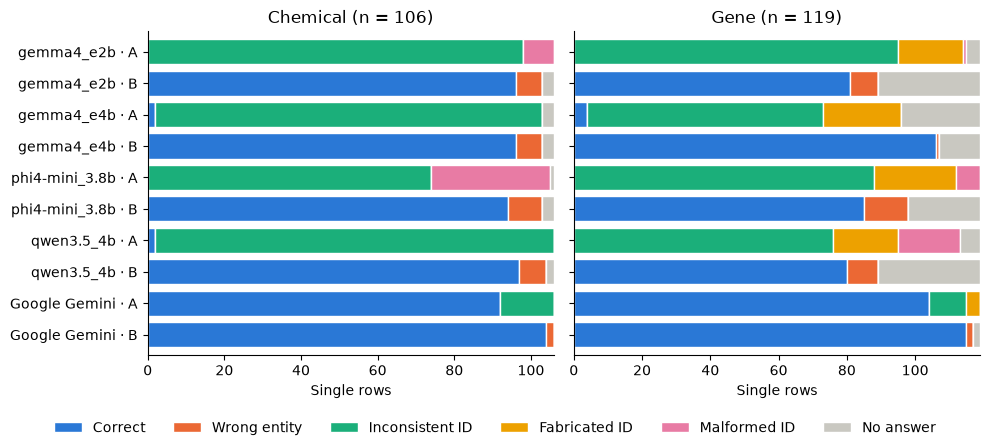

In [38]:
# Claude Opus 5.5 (Anthropic) wrote this cell (14.10.2026). Claude was asked to assist in the visualization of the headline data using a bar chart.
# Prompt: Create a bar chart visualizing the combined data from final_headline as well as arm_a_headline. All outcome groups should be clearly visible, in particular
# the differences between the arms.
# Inputs: This file up until this cell.

outcome_groups = {
    "correct": "Correct",
    "wrong_entity": "Wrong entity",
    "inconsistent": "Inconsistent ID",
    "fabricated": "Fabricated ID",
    "malformed": "Malformed ID",
    "abstained": "No answer",
    "abstain_no_match": "No answer",
    "abstain_multiple": "No answer",
}
group_colors = {"Correct": "#2a78d6", "Wrong entity": "#eb6834", "Inconsistent ID": "#1baf7a",
                "Fabricated ID": "#eda100", "Malformed ID": "#e87ba4", "No answer": "#c9c8c1"}
model_order = ["gemma4_e2b", "gemma4_e4b", "phi4-mini_3.8b", "qwen3.5_4b", "Google Gemini"]

a_part = arm_a[arm_a["id_status"] == "single"][["model", "entity_type", "outcome"]].assign(arm="A")
b_part = arm_b[(arm_b["id_status"] == "single") & (arm_b["model"].isin(model_order))][["model", "entity_type", "outcome"]].assign(arm="B")
outcomes_ab = pd.concat([a_part, b_part], ignore_index=True)
outcomes_ab["group"] = outcomes_ab["outcome"].map(outcome_groups)
assert outcomes_ab["group"].notna().all()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, entity_type in zip(axes, ["chemical", "gene"]):
    subset = outcomes_ab[outcomes_ab["entity_type"] == entity_type]
    counts = pd.crosstab([subset["model"], subset["arm"]], subset["group"])
    counts = counts.reindex(columns=list(group_colors), fill_value=0)
    counts = counts.reindex([(model, arm) for model in model_order for arm in ["A", "B"]])
    counts.index = [f"{model} · {arm}" for model, arm in counts.index]
    counts.plot.barh(stacked=True, ax=ax, color=list(group_colors.values()), width=0.8,
                     edgecolor="white", linewidth=1, legend=False)
    ax.set_title(f"{entity_type.capitalize()} (n = {len(subset) // (2 * len(model_order))})")
    ax.set_xlabel("Single rows")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(f"{FINAL_PATH}/fig_outcomes_ab.pdf")

In [39]:
none_rows = combined[combined["id_status"] == "none"]
pd.crosstab([none_rows["entity_type"], none_rows["method"]], none_rows["outcome"])

outcome                         abstained_on_none  returned_on_none
entity_type method                                                 
chemical    B1b                                 9                 1
            B2                                  3                 7
            B3                                  9                 1
            B_Google Gemini                     9                 1
            B_gemma4_e2b                        9                 1
            B_gemma4_e4b                        7                 3
            B_gemma4_e4b_think                  9                 1
            B_phi4-mini_3.8b                    8                 2
            B_qwen3.5_4b                        7                 3
gene        B1b                                 8                 0
            B2                                  5                 3
            B3                                  8                 0
            B_Google Gemini                     6                 2
            B_gemma4_e2b                        4                 4
            B_gemma4_e4b                        7                 1
            B_gemma4_e4b_think                  8                 0
            B_phi4-mini_3.8b                    5                 3
            B_qwen3.5_4b                        8                 0

In [40]:
ambi_rows = combined[combined["id_status"] == "ambiguous"]
pd.crosstab([ambi_rows["entity_type"], ambi_rows["method"]], ambi_rows["outcome"])

outcome                         abstain_multiple  abstain_no_match  correct  \
entity_type method                                                            
chemical    B1b                                2                17       17   
            B2                                 8                 0       23   
            B3                                 2                14       18   
            B_Google Gemini                    0                 2       32   
            B_gemma4_e2b                       1                 6       31   
            B_gemma4_e4b                       1                 8       28   
            B_gemma4_e4b_think                 0                 6       29   
            B_phi4-mini_3.8b                   0                 2       31   
            B_qwen3.5_4b                       1                 3       31   
gene        B1b                                1                13       11   
            B2                                 8                 0       12   
            B3                                 1                13       11   
            B_Google Gemini                    0                 2       22   
            B_gemma4_e2b                       1                10       13   
            B_gemma4_e4b                       0                 5       17   
            B_gemma4_e4b_think                 1                 6       15   
            B_phi4-mini_3.8b                   0                16        9   
            B_qwen3.5_4b                       0                11       13   

outcome                         wrong_entity  
entity_type method                            
chemical    B1b                           10  
            B2                            15  
            B3                            12  
            B_Google Gemini               12  
            B_gemma4_e2b                   8  
            B_gemma4_e4b                   9  
            B_gemma4_e4b_think            11  
            B_phi4-mini_3.8b              13  
            B_qwen3.5_4b                  11  
gene        B1b                            5  
            B2                            10  
            B3                             5  
            B_Google Gemini                6  
            B_gemma4_e2b                   6  
            B_gemma4_e4b                   8  
            B_gemma4_e4b_think             8  
            B_phi4-mini_3.8b               5  
            B_qwen3.5_4b                   6

In [41]:
# Comparison between arm A and arm B; we will use this as the input to our McNemar test
a_pair = arm_a[arm_a["id_status"] == "single"][["id", "model", "entity_type", "outcome"]]
b_pair = arm_b[arm_b["id_status"] == "single"][["id", "model", "outcome"]]
paired = pd.merge(a_pair, b_pair, on=["id", "model"], suffixes=("_a", "_b"), validate="one_to_one")
assert len(paired) == 5 * (106 + 119)

wrong_in_a = ["fabricated", "inconsistent", "wrong_entity", "malformed"]
pair_grouped = paired.groupby(["entity_type", "model"])

arch_table = pd.DataFrame({
    "Entity type": [key[0] for key, group in pair_grouped],
    "Model": [key[1] for key, group in pair_grouped],
    "n": [len(group) for key, group in pair_grouped],
    "Correct (A)": [(group["outcome_a"] == "correct").sum() for key, group in pair_grouped],
    "Correct (B)": [(group["outcome_b"] == "correct").sum() for key, group in pair_grouped],
    "Only A": [((group["outcome_a"] == "correct") & (group["outcome_b"] != "correct")).sum() for key, group in pair_grouped],
    "Only B": [((group["outcome_a"] != "correct") & (group["outcome_b"] == "correct")).sum() for key, group in pair_grouped],
    "Wrong ID (A)": [group["outcome_a"].isin(wrong_in_a).sum() for key, group in pair_grouped],
    "Wrong ID (B)": [(group["outcome_b"] == "wrong_entity").sum() for key, group in pair_grouped],
})
arch_table

,Entity type,Model,n,Correct (A),Correct (B),Only A,Only B,Wrong ID (A),Wrong ID (B)
0,chemical,Google Gemini,106,92,104,0,12,14,2
1,chemical,gemma4_e2b,106,0,96,0,96,106,7
2,chemical,gemma4_e4b,106,2,96,0,94,101,7
3,chemical,phi4-mini_3.8b,106,0,94,0,94,105,9
4,chemical,qwen3.5_4b,106,2,97,0,95,104,7
5,gene,Google Gemini,119,104,115,2,13,15,2
6,gene,gemma4_e2b,119,0,81,0,81,115,8
7,gene,gemma4_e4b,119,4,106,0,102,92,1
8,gene,phi4-mini_3.8b,119,0,85,0,85,119,13
9,gene,qwen3.5_4b,119,0,80,0,80,113,9


### Contingency table

| | Correct (B) | Incorrect (B) |
| -- | -- | -- |
| Correct (A) | both correct | A only |
| Incorrect (A) | B only | neither correct |

In [42]:
def mcnemar_test(a_correct, b_correct):
    only_a = (a_correct & ~b_correct).sum()
    only_b = (~a_correct & b_correct).sum()

    table = [
        [(a_correct & b_correct).sum(), only_a],
        [only_b, (~a_correct & ~b_correct).sum()],
    ]

    return only_a, only_b, mcnemar(table, exact=True).pvalue

In [43]:
#McNemar test comparing arm A to arm B for each entity type and each model
nemar_rows = []

for key, group in pair_grouped:
    entity_type, model = key
    a_correct, b_correct = group["outcome_a"] == "correct", group["outcome_b"] == "correct"

    only_a, only_b, p = mcnemar_test(a_correct, b_correct)
    nemar_rows.append([entity_type, model, len(group), only_a, only_b, p])

a_vs_b = pd.DataFrame(nemar_rows, columns=["Entity type", "Model", "n", "Only A", "Only B", "p-value"])


a_vs_b_display = a_vs_b.copy()
a_vs_b_display["p-value"] = ["< 0.0001" if p < 0.0001 else round(p, 4) for p in a_vs_b["p-value"]]
a_vs_b_display

,Entity type,Model,n,Only A,Only B,p-value
0,chemical,Google Gemini,106,0,12,0.0005
1,chemical,gemma4_e2b,106,0,96,< 0.0001
2,chemical,gemma4_e4b,106,0,94,< 0.0001
3,chemical,phi4-mini_3.8b,106,0,94,< 0.0001
4,chemical,qwen3.5_4b,106,0,95,< 0.0001
5,gene,Google Gemini,119,2,13,0.0074
6,gene,gemma4_e2b,119,0,81,< 0.0001
7,gene,gemma4_e4b,119,0,102,< 0.0001
8,gene,phi4-mini_3.8b,119,0,85,< 0.0001
9,gene,qwen3.5_4b,119,0,80,< 0.0001


Our results show that arm B is significantly better across the board than arm A at $p=0.01$

In the following we perform some extra tests to also compare against B3, Gemma 2B vs 4B, and Gemma 4B with thinking on vs off. These tests are only exploratory

In [44]:
def paired_methods(frame, method_1, method_2, entity_type):
    single = frame[(frame["id_status"] == "single") & (frame["entity_type"] == entity_type)]
    m1 = single[single["method"] == method_1][["id", "outcome"]]
    m2 = single[single["method"] == method_2][["id", "outcome"]]
    pair = pd.merge(m1, m2, on="id", suffixes=("_1", "_2"), validate="one_to_one")

    return mcnemar_test(pair["outcome_1"] == "correct", pair["outcome_2"] == "correct")


comps = []
comps.append(("B_gemma4_e2b", "B2"))
comps.append(("B_gemma4_e2b", "B3"))
comps.append(("B_gemma4_e4b", "B2"))
comps.append(("B_gemma4_e4b", "B3"))
comps.append(("B_phi4-mini_3.8b", "B2"))
comps.append(("B_phi4-mini_3.8b", "B3"))
comps.append(("B_qwen3.5_4b", "B2"))
comps.append(("B_qwen3.5_4b", "B3"))
comps.append(("B_Google Gemini", "B2"))
comps.append(("B_gemma4_e4b", "B_gemma4_e2b"))
comps.append(("B_gemma4_e4b_think", "B_gemma4_e4b"))

test_rows = []
for method_1, method_2 in comps:
    for entity_type in ["chemical", "gene"]:
        only_1, only_2, p = paired_methods(combined, method_1, method_2, entity_type)
        test_rows.append([method_1, method_2, entity_type, only_1, only_2, round(p, 4)])

test_table = pd.DataFrame(test_rows, columns=["Method 1", "Method 2", "Entity type", "Only 1", "Only 2", "p-value"])
test_table_display = test_table.copy()
test_table_display["p-value"] = ["< 0.0001" if p < 0.0001 else round(p, 4) for p in test_table["p-value"]]
test_table_display

,Method 1,Method 2,Entity type,Only 1,Only 2,p-value
0,B_gemma4_e2b,B2,chemical,13,8,0.3833
1,B_gemma4_e2b,B2,gene,17,17,1.0
2,B_gemma4_e2b,B3,chemical,32,4,< 0.0001
3,B_gemma4_e2b,B3,gene,40,11,0.0001
4,B_gemma4_e4b,B2,chemical,12,7,0.3593
5,B_gemma4_e4b,B2,gene,28,3,< 0.0001
6,B_gemma4_e4b,B3,chemical,33,5,< 0.0001
7,B_gemma4_e4b,B3,gene,55,1,< 0.0001
8,B_phi4-mini_3.8b,B2,chemical,11,8,0.6476
9,B_phi4-mini_3.8b,B2,gene,22,18,0.6358


Next, we will check name accuracy (Predicted name == (canonical_name or clean_form))

In [45]:
arm_b_grouped = arm_b[arm_b["id_status"] == "single"].groupby(["entity_type", "model"])

canonical_matches = []
clean_matches = []
entity_matches = []
for key, value in arm_b_grouped:
    n_strict = 0
    n_lenient = 0
    n_entity_type = 0
    for row in value.itertuples():
        entity_type_match = row.pred_entity_type == row.entity_type
        if row.entity_type == "chemical":
            strict = row.pred_name.casefold() == row.canonical_name.casefold()
            clean = row.pred_name.casefold() == row.clean_form.casefold()
        else:
            strict = row.pred_name == row.canonical_name
            clean = row.pred_name == row.clean_form
        if entity_type_match:
            n_entity_type += 1
        if strict:
            n_strict += 1
        if strict or clean:
            n_lenient += 1
    canonical_matches.append(n_strict)
    clean_matches.append(n_lenient)
    entity_matches.append(n_entity_type)

name_matches_b = pd.DataFrame({
    "Entity Type": [key[0] for key, group in arm_b_grouped],
    "Model": [key[1] for key, group in arm_b_grouped],
    "n": [len(group) for key, group in arm_b_grouped],
    "Match to canonical name": canonical_matches,
    "Match to canonical or clean name": clean_matches,
    "Match to entity type": entity_matches,
    "ID correct": [(group["outcome"] == "correct").sum() for key, group in arm_b_grouped],
})

name_matches_b

,Entity Type,Model,n,Match to canonical name,Match to canonical or clean name,Match to entity type,ID correct
0,chemical,Google Gemini,106,90,92,106,104
1,chemical,gemma4_e2b,106,72,80,105,96
2,chemical,gemma4_e4b,106,72,79,103,96
3,chemical,gemma4_e4b_think,106,70,79,106,95
4,chemical,phi4-mini_3.8b,106,70,76,106,94
5,chemical,qwen3.5_4b,106,78,87,106,97
6,gene,Google Gemini,119,114,115,116,115
7,gene,gemma4_e2b,119,59,61,108,81
8,gene,gemma4_e4b,119,94,94,111,106
9,gene,gemma4_e4b_think,119,77,77,107,92


In [46]:
arm_a_grouped = arm_a[arm_a["id_status"] == "single"].groupby(["entity_type", "model"])

canonical_matches = []
clean_matches = []
entity_matches = []
for key, value in arm_a_grouped:
    n_strict = 0
    n_lenient = 0
    n_entity_type = 0
    for row in value.itertuples():
        entity_type_match = row.pred_entity_type == row.entity_type
        if row.entity_type == "chemical":
            strict = row.pred_name.casefold() == row.canonical_name.casefold()
            clean = row.pred_name.casefold() == row.clean_form.casefold()
        else:
            strict = row.pred_name == row.canonical_name
            clean = row.pred_name == row.clean_form
        if entity_type_match:
            n_entity_type += 1
        if strict:
            n_strict += 1
        if strict or clean:
            n_lenient += 1
    canonical_matches.append(n_strict)
    clean_matches.append(n_lenient)
    entity_matches.append(n_entity_type)

name_matches_a = pd.DataFrame({
    "Entity Type": [key[0] for key, group in arm_a_grouped],
    "Model": [key[1] for key, group in arm_a_grouped],
    "n": [len(group) for key, group in arm_a_grouped],
    "Match to canonical name": canonical_matches,
    "Match to canonical or clean name": clean_matches,
    "Match to entity type": entity_matches,
    "ID correct": [(group["outcome"] == "correct").sum() for key, group in arm_a_grouped],
})

name_matches_a

,Entity Type,Model,n,Match to canonical name,Match to canonical or clean name,Match to entity type,ID correct
0,chemical,Google Gemini,106,93,95,106,92
1,chemical,gemma4_e2b,106,72,79,105,0
2,chemical,gemma4_e4b,106,72,78,105,2
3,chemical,phi4-mini_3.8b,106,72,78,106,0
4,chemical,qwen3.5_4b,106,77,85,106,2
5,gene,Google Gemini,119,117,117,117,104
6,gene,gemma4_e2b,119,39,43,106,0
7,gene,gemma4_e4b,119,77,77,106,4
8,gene,phi4-mini_3.8b,119,57,59,106,0
9,gene,qwen3.5_4b,119,36,39,108,0


In [47]:
# Load the runs into memory like in the generation notebooks
arms = ['A', 'B']
models = ['gemma4_e2b', 'gemma4_e4b', 'phi4-mini_3.8b', 'qwen3.5_4b', 'Google Gemini'] # As per file name in /runs
runs_data = [
    {
        'arm': arm,
        'model': model,
        'path': f"{RUNS_PATH}/eco-id-results-{arm}-{model}.csv"
    }
    for arm in arms
    for model in models
]

# Think run
runs_data.append({
    'arm': 'B',
    'model': 'gemma4_e4b_think',
    'path': f"{RUNS_PATH}/eco-id-results-B-gemma4_e4b_think.csv"
})


# Check file rows match up with benchmark after run
# Then add the ID column to the run data


for run in runs_data:
    run['df'] = load_run(run['path'], run['arm'], benchmark)

In [48]:
time_rows = []

for run in runs_data:
    run['df'] = load_run(run['path'], run['arm'], benchmark)
    if run['model'] == "Google Gemini":
        gemini_seconds = run['df']['total_duration'].astype(float) / 1e9
        time_rows.append([run['model'], run['arm'],
                          round(gemini_seconds.median(), 1),
                          "n/a", "n/a", "n/a",
                          round(gemini_seconds.sum() / 60, 1)])
        continue
    total = run['df']['total_duration'].astype(float)
    load = run['df']['load_duration'].astype(float)
    eval_count = run['df']['eval_count'].astype(float)
    eval_duration = run['df']['eval_duration'].astype(float)
    prompt_count = run['df']['prompt_eval_count'].astype(float)
    prompt_duration = run['df']["prompt_eval_duration"].astype(float)
    assert (eval_duration > 0).all() and (prompt_duration > 0).all(), (run['model'], run['arm'])

    input_tokens_per_sec = prompt_count / (prompt_duration / 1e9)
    tokens_per_sec = eval_count / (eval_duration / 1e9)
    seconds_per_item = (total - load) / 1e9

    time_rows.append([run['model'], run['arm'],
                        round(seconds_per_item.median(), 1),
                        round(tokens_per_sec.median(), 1),
                        round(input_tokens_per_sec.median(), 1),
                        round(eval_count.median()),
                        round(seconds_per_item.sum() / 60, 1)])

runtime_table = pd.DataFrame(time_rows, columns=["Model", "arm", "Second per items, median", "Tokens/s, median",
                                                 "Token/s (input), median", "eval_count", "Total duration (min)"])
runtime_table

,Model,arm,"Second per items, median","Tokens/s, median","Token/s (input), median",eval_count,Total duration (min)
0,gemma4_e2b,A,7.8,5.9,98.5,36,41.7
1,gemma4_e4b,A,10.3,5.1,49.2,35,54.9
2,phi4-mini_3.8b,A,3.6,11.5,731.3,38,19.2
3,qwen3.5_4b,A,7.1,9.0,56.8,35,37.9
4,Google Gemini,A,1.2,n/a,n/a,n/a,6.9
5,gemma4_e2b,B,4.9,7.2,98.2,25,26.1
6,gemma4_e4b,B,6.8,6.1,49.2,25,37.3
7,phi4-mini_3.8b,B,2.3,11.7,587.6,24,12.5
8,qwen3.5_4b,B,5.1,9.3,56.8,24,28.0
9,Google Gemini,B,1.2,n/a,n/a,n/a,6.6


**Notes about the runtime**:
- Gemini's numbers include the round trip over the API (including network latency).
- Gemma's speculative decoding was on

B1 and B3 ran in seconds with cached data, while B2 took 40 minutes and 50s.



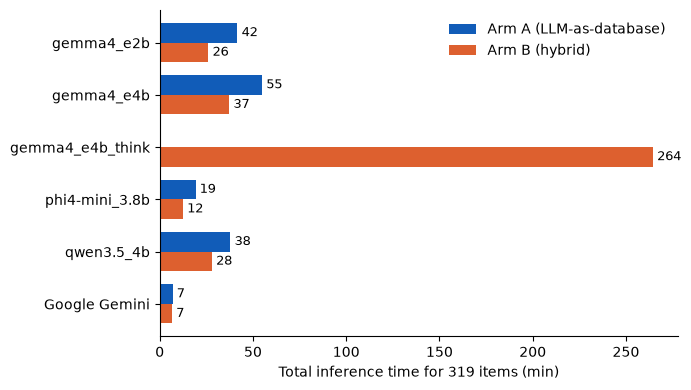

In [49]:
# Claude Opus 5.5 (Anthropic) wrote this cell (14.10.2026). Claude was asked to assist in the visualization of the runtime data using a bar chart.
# Prompt: Create a simple bar chart visualizing the runtimes of each run. The differences between arm A and arm B should be visible.
# Inputs: This file up until this cell.

order = ["gemma4_e2b", "gemma4_e4b", "gemma4_e4b_think", "phi4-mini_3.8b", "qwen3.5_4b", "Google Gemini"]
runtime_wide = runtime_table.pivot(index="Model", columns="arm", values="Total duration (min)").reindex(order)

ax = runtime_wide.plot.barh(color=["#115cb8", "#dd602f"], width=0.75, figsize=(7, 4))
for bars, arm in zip(ax.containers, runtime_wide.columns):
    ax.bar_label(bars, labels=["" if pd.isna(v) else f"{v:.0f}" for v in runtime_wide[arm]], padding=3, fontsize=9)
ax.invert_yaxis()
ax.set_ylabel("")
ax.set_xlabel("Total inference time for 319 items (min)") # Edited text
ax.legend(["Arm A (LLM-as-database)", "Arm B (hybrid)"], frameon=False) # Edited text
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FINAL_PATH}/runtime_total.pdf")

# Failure analysis

# Arm A

In [57]:
none_returned = arm_a[arm_a["outcome"] == "returned_on_none"].copy()

def a_fail_decide(row):
    if row["id_format"] != "valid":
        return "Malformed ID"
    if row["exists"] == "False":
        return "Fabricated ID"
    if row["name_in_entry"] == "False":
        return "Inconsistent ID"
    return "Consistent but wrong"

none_returned["none_label"] = none_returned.apply(a_fail_decide, axis=1)
pd.crosstab(none_returned["none_label"], none_returned["model"], margins=True)

model,Google Gemini,gemma4_e2b,gemma4_e4b,phi4-mini_3.8b,qwen3.5_4b,All
none_label,,,,,,
Consistent but wrong,3,0,0,0,0,3
Fabricated ID,0,3,0,2,1,6
Inconsistent ID,12,14,9,6,8,49
Malformed ID,0,0,0,8,1,9
All,15,17,9,16,10,67


### Examples

Examples have been chosen below to illustrate typical failures in each class.
1. Fabricated ID: LLM resolves `EGFR` to HGNC:1061, which does not exist and is made up
2. Inconsistent ID: LLM resolves `hydroxyurea` to CID 6111, which exists but is an entirely different compound
3. Double inconsistent ID: LLM now also resolves `xanhtine` to 6111.
4. Malformed ID: Typical Qwen malformed output, putting the HGNC ID in square brackets
5. Return on none: An ID was returned besides not being in the data set, it also passed internal checks (name matches ID, but no ID should've been returned)

In [51]:
a_examples = [
    ("GENE-002", "gemma4_e2b"),
    ("CHEM-003", "gemma4_e2b"),
    ("CHEM-008", "gemma4_e2b"), 
    ("GENE-001", "qwen3.5_4b"), 
    ("CHEM-153", "Google Gemini"),
]

a_cols = ["id", "model", "input", "pred_name", "identifier", "accepted_id", "outcome"]
a_example_rows = []
for example_id, example_model in a_examples:
    row = arm_a[(arm_a["id"] == example_id) & (arm_a["model"] == example_model)]
    a_example_rows.append(row[a_cols].iloc[0])

pd.DataFrame(a_example_rows)

,id,model,input,pred_name,identifier,accepted_id,outcome
163,GENE-002,gemma4_e2b,EFGR,EGFR,HGNC:1061,HGNC:3236,fabricated
2,CHEM-003,gemma4_e2b,hydroxyureaa,hydroxyurea,6111,3657,inconsistent
7,CHEM-008,gemma4_e2b,xanhtine,xanthine,6111,1188,inconsistent
1119,GENE-001,qwen3.5_4b,TP35,TP35,HGNC:[10246],HGNC:11998,malformed
1428,CHEM-153,Google Gemini,hydroxyureine,hydroxyurea,3657,,returned_on_none


# Arm B

In [52]:
def b_fail_decide(row):
    if row["outcome"] == "returned_on_none":
        return "Returned on none"
    if row["llm_abstain"] == "True":
        return "LLM abstained"
    if row["pred_entity_type"] != row["entity_type"]:
        return "Wrong predicted entity type"
    if row["outcome"] == "abstain_multiple":
        return "Abstain on multiple"
    if row["pred_name"] == row["canonical_name"]:
        return "Match on canonical, could not retrieve"
    if (row["pred_name"] == row["clean_form"]):
        return "Match on clean form, could not retrieve"
    if row["outcome"] == "abstain_no_match":
        return "Abstained on no match"
    return "Other" # Decision could not be made

arm_b_failed = arm_b[(arm_b["id_status"] == "single") & (arm_b["outcome"] != "correct")]
arm_b_failed["decision"] = arm_b_failed.apply(b_fail_decide, axis=1)
#arm_b_failed[arm_b_failed["decision"] == "other"].to_csv(f"{FINAL_PATH}/failure_analysis_to_decide.csv", index=False)

The decisions marked with `other` were manually annotated and fed back.

In [53]:
manual_decisions = pd.read_csv(f"{FINAL_PATH}/failure_analysis_decisions.csv", dtype=str, keep_default_na=False)

manual = manual_decisions[["id", "model", "manual_decision"]]

arm_b_failed = pd.merge(arm_b_failed, manual, on=["id", "model"], how="left", validate="one_to_one")

arm_b_failed["final_decision"] = arm_b_failed["decision"]
arm_b_failed.loc[arm_b_failed["decision"] == "Other", "final_decision"] = arm_b_failed["manual_decision"]


In [54]:
pd.crosstab(arm_b_failed["final_decision"], arm_b_failed["model"], margins=True)

model,Google Gemini,gemma4_e2b,gemma4_e4b,gemma4_e4b_think,phi4-mini_3.8b,qwen3.5_4b,All
final_decision,,,,,,,
Abstain on multiple,0,2,0,1,3,0,6
Abstained on no match,1,21,0,5,7,16,50
LLM abstained,1,4,13,22,0,10,50
"Match on clean form, could not retrieve",1,1,1,2,2,1,8
Wrong predicted entity type,2,10,3,4,22,9,50
close_relative,1,5,4,2,8,7,27
variant,0,1,0,1,2,2,6
wrong,0,4,2,1,2,3,12
All,6,48,23,38,46,48,209


In [55]:
local_failed = arm_b_failed[~arm_b_failed["model"].isin(["Google Gemini", "gemma4_e4b_think"])]
pd.crosstab(local_failed["final_decision"], [local_failed["entity_type"], local_failed["noise_type"]])

entity_type                                 chemical                    \
noise_type                              abbreviation separator synonym   
final_decision                                                           
Abstain on multiple                                0         0       0   
Abstained on no match                              1         0       0   
LLM abstained                                      1         0       0   
Match on clean form, could not retrieve            0         1       0   
Wrong predicted entity type                        2         0       0   
close_relative                                     1         0       4   
variant                                            0         1       0   
wrong                                              1         0       2   

entity_type                                                             \
noise_type                              tool_artifact typo unperturbed   
final_decision                                                           
Abstain on multiple                                 0    0           0   
Abstained on no match                               1    2           0   
LLM abstained                                       0    1           0   
Match on clean form, could not retrieve             2    2           0   
Wrong predicted entity type                         0    0           1   
close_relative                                      7    4           0   
variant                                             2    1           1   
wrong                                               0    0           0   

entity_type                                                gene         \
noise_type                              word_order abbreviation casing   
final_decision                                                           
Abstain on multiple                              1            0      0   
Abstained on no match                            1            5      1   
LLM abstained                                    1            0      0   
Match on clean form, could not retrieve          0            0      0   
Wrong predicted entity type                      0            3      1   
close_relative                                   0            0      1   
variant                                          0            0      0   
wrong                                            0            1      0   

entity_type                                                                   \
noise_type                              separator synonym tool_artifact typo   
final_decision                                                                 
Abstain on multiple                             0       3             0    1   
Abstained on no match                          10       9             1    9   
LLM abstained                                   0       2            12    6   
Match on clean form, could not retrieve         0       0             0    0   
Wrong predicted entity type                     3      11             9    6   
close_relative                                  2       2             0    0   
variant                                         0       0             0    0   
wrong                                           3       2             0    1   

entity_type                                         
noise_type                              word_order  
final_decision                                      
Abstain on multiple                              0  
Abstained on no match                            4  
LLM abstained                                    4  
Match on clean form, could not retrieve          0  
Wrong predicted entity type                      8  
close_relative                                   3  
variant                                          0  
wrong                                            1

In [56]:
b_examples = [
    ("GENE-141", "gemma4_e2b"),
    ("GENE-098", "gemma4_e2b"),
    ("GENE-104", "phi4-mini_3.8b"),
    ("CHEM-014", "Google Gemini"),
    ("GENE-017", "gemma4_e2b"),
    ("CHEM-005", "phi4-mini_3.8b"),
    ("CHEM-095", "gemma4_e2b"),
]

b_cols = ["id", "model", "input", "pred_name", "pred_entity_type", "canonical_name", "candidate_ids", "final_decision"]
b_example_rows = []
for example_id, example_model in b_examples:
    row = arm_b_failed[(arm_b_failed["id"] == example_id) & (arm_b_failed["model"] == example_model)]
    b_example_rows.append(row[b_cols].iloc[0])

pd.DataFrame(b_example_rows)

,id,model,input,pred_name,pred_entity_type,canonical_name,candidate_ids,final_decision
43,GENE-141,gemma4_e2b,1-Mar,,chemical,MARCHF1,0,LLM abstained
31,GENE-098,gemma4_e2b,PSA,Prostate-specific antigen,chemical,KLK3,,Wrong predicted entity type
105,GENE-104,phi4-mini_3.8b,Nrf2,Nrf2,gene,NFE2L2,HGNC:7782;HGNC:4071,Abstain on multiple
165,CHEM-014,Google Gemini,tetrahydrobiooterin,tetrahydrobiopterin,chemical,"(6R)-5,6,7,8-tetrahydrobiopterin",135402045,"Match on clean form, could not retrieve"
14,GENE-017,gemma4_e2b,interlukin 6,INTERLEKIN,gene,IL6,,Abstained on no match
71,CHEM-005,phi4-mini_3.8b,sperrmine,spermidine,chemical,spermine,1102,close_relative
4,CHEM-095,gemma4_e2b,muriatic acid,sulfuric acid,chemical,hydrochloric acid,1118,wrong


### Examples

Examples have been chosen below to illustrate typical failures in each class.
1. LLM abstained: LLM marked the entity as an abstention even though it should have resolved to a name
2. Wrong predicted entity type: Wrong type classification leads to wrong API routing.
3. Multiple candidates: Multiple candidates were retrieved, so retrieval layer abstained
4. clean_form match: The clean form was correctly resolved, but the retrieval layer could not get the ID from it alone
5. No match found: Abstains because no match was found via the API
6. close_relative: Closely related chemical (family) was resolved, but not the one in question
7. Wrong: Wrong resolution of name